In [15]:

from collections import Counter
from collections import defaultdict

# Base
import math as m

# Base 2.0
import numpy as np
import pandas as pd

# Grafici
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D

# SciPy
from scipy import stats
from scipy.cluster.hierarchy import (
    dendrogram,
    fcluster,
    linkage,
)
from scipy.spatial.distance import pdist, squareform

# Scikit-learn
from sklearn.cluster import (
    AgglomerativeClustering,
    BisectingKMeans,
    cluster_optics_dbscan,
    DBSCAN,
    KMeans,
    OPTICS,
)
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, KNNImputer

from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    RidgeCV,
    Lasso,
    LassoCV,
)
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    roc_auc_score,
    r2_score,
    RocCurveDisplay,
    silhouette_score,
    silhouette_samples,
)
from sklearn.model_selection import (
    cross_val_score,
    train_test_split,
)
from sklearn.naive_bayes import (
    CategoricalNB,
    GaussianNB,
)
from sklearn.neighbors import (
    KNeighborsClassifier,
    NearestNeighbors,
    KNeighborsRegressor,
)
from sklearn.preprocessing import (
    MinMaxScaler,
    StandardScaler,
)
from sklearn.tree import (
    DecisionTreeClassifier,
    DecisionTreeRegressor,
    plot_tree,
)
from pyod.models.knn import KNN
from scipy.spatial.distance import pdist, squareform
from tqdm import tqdm

# Librerie
import pandas as pd
import numpy as np

# High Dimensionality
from pyod.models.abod import ABOD

# Ensemble
from pyod.models.feature_bagging import FeatureBagging
# carico LOF per FeaBag, chiaramente si può cambiare a seconda del modello semplice scelto
from pyod.models.lof import LOF
from pyod.models.loda import LODA

# Foreste
from sklearn.ensemble import IsolationForest
from isotree import IsolationForest as EIF

from sklearn.manifold import TSNE


In [16]:
df = pd.read_csv("a_cmi_internet.csv")
#legenda = pd.read_csv("data_dictionary.csv")

# Stagioni enceoded winter=0, spring=1, summer=2, autumn=3
df_da_imp= df.copy()

# Tracking dei missing values per SDS raw per la futura regressione
df_da_imp['sds_imputed_mask'] = df_da_imp['SDS-SDS_Total_Raw'].isna()

# Filter age <= 18
df_da_imp = df_da_imp[df_da_imp["Basic_Demos-Age"] <= 18]

### SII (Severity Impairment Index) Distribution by Sex (Basic_Demos-Sex)

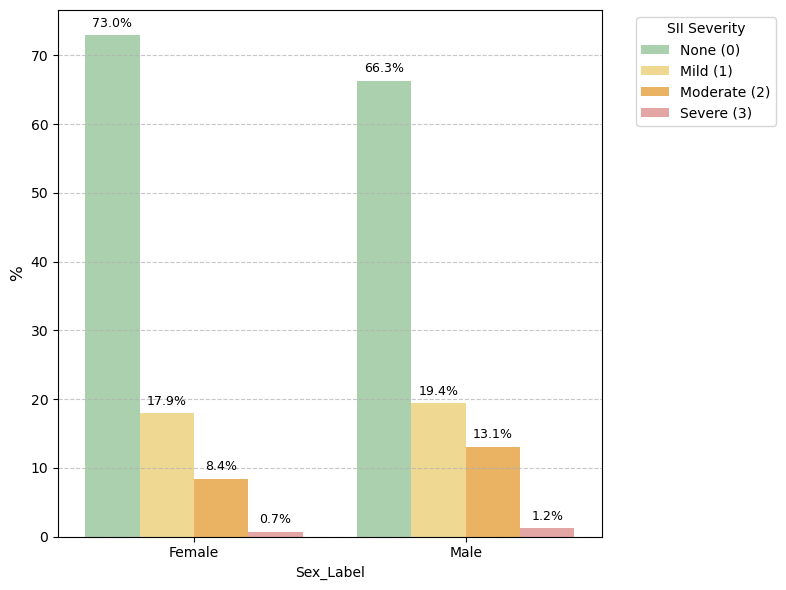

In [17]:
# Analysis of sii value distribution by sex (Basic_Demos-Sex)
# 0 = Male, 1 = Female
# sii: 0 = None, 1 = Mild, 2 = Moderate, 3 = Severe

# Map labels for readability
plot_df = df_da_imp.copy()
plot_df['Sex_Label'] = plot_df['Basic_Demos-Sex'].map({0: 'Male', 1: 'Female'})
plot_df['SII_Label'] = plot_df['sii'].map({0.0: 'None (0)', 1.0: 'Mild (1)', 2.0: 'Moderate (2)', 3.0: 'Severe (3)'})

# Fixed order for categories and soft/modern custom palette
sii_order = ['None (0)', 'Mild (1)', 'Moderate (2)', 'Severe (3)']
custom_palette = ["#A5D6A7", "#FFE082", "#FFB74D", "#EF9A9A"] # soft green, amber, orange, red

# Calculate relative percentages within each sex group
prop_df = (
    plot_df.groupby('Sex_Label')['SII_Label']
    .value_counts(normalize=True)
    .rename('Percentage')
    .mul(100)
    .reset_index()
)

# Create single plot
fig, ax = plt.subplots(figsize=(8, 6))

sns.barplot(
    data=prop_df, 
    x='Sex_Label', 
    y='Percentage', 
    hue='SII_Label', 
    hue_order=sii_order,
    palette=custom_palette, 
    ax=ax
)

# Apply user layout choices:
# ax.set_title('Relative Distribution (%) of SII by Sex', fontsize=14, fontweight='bold', pad=15)
# ax.set_xlabel('Sex', fontsize=12, labelpad=10)
ax.set_ylabel('%', fontsize=12)

# Show legend and grid
ax.legend(title='SII Severity', bbox_to_anchor=(1.05, 1), loc='upper left')
ax.grid(axis='y', linestyle='--', alpha=0.7)

# Add percentage labels on top of bars
for p in ax.patches:
    height = p.get_height()
    if not np.isnan(height) and height > 0:
        ax.annotate(
            f'{height:.1f}%',
            xy=(p.get_x() + p.get_width() / 2, height),
            xytext=(0, 4),
            textcoords="offset points",
            ha='center', va='bottom', fontsize=9
        )

plt.tight_layout()
plt.show()

### SII (Severity Impairment Index) Distribution by Age Groups (Basic_Demos-Age)

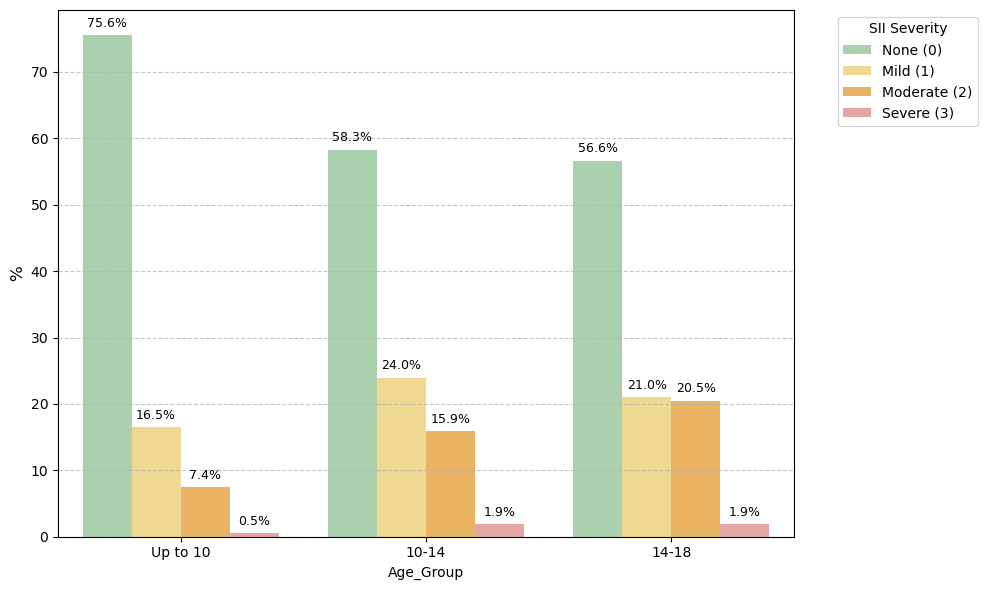

In [18]:
# Analysis of sii value distribution by age groups (Basic_Demos-Age)
# Bins: Up to 10, 10-14, 14-18 (since age <= 18)

# Prepare data for plotting
plot_df = df_da_imp.copy()
plot_df['SII_Label'] = plot_df['sii'].map({0.0: 'None (0)', 1.0: 'Mild (1)', 2.0: 'Moderate (2)', 3.0: 'Severe (3)'})

# Define age bins in English
def bin_age(age):
    if age <= 10:
        return 'Up to 10'
    elif 10 < age <= 14:
        return '10-14'
    else:
        return '14-18'

plot_df['Age_Group'] = plot_df['Basic_Demos-Age'].apply(bin_age)

# Fixed order for categories
sii_order = ['None (0)', 'Mild (1)', 'Moderate (2)', 'Severe (3)']
age_order = ['Up to 10', '10-14', '14-18']
custom_palette = ["#A5D6A7", "#FFE082", "#FFB74D", "#EF9A9A"] # soft green, amber, orange, red

# Calculate relative percentages within each age group
prop_df = (
    plot_df.groupby('Age_Group')['SII_Label']
    .value_counts(normalize=True)
    .rename('Percentage')
    .mul(100)
    .reset_index()
)

# Create single plot
fig, ax = plt.subplots(figsize=(10, 6))

sns.barplot(
    data=prop_df, 
    x='Age_Group', 
    y='Percentage', 
    order=age_order,
    hue='SII_Label', 
    hue_order=sii_order,
    palette=custom_palette, 
    ax=ax
)

# Apply user layout choices:
# ax.set_title('Relative Distribution (%) of SII by Age Group', fontsize=14, fontweight='bold', pad=15)
# ax.set_xlabel('Age Group', fontsize=12, labelpad=10)
ax.set_ylabel('%', fontsize=12)

# Show legend and grid
ax.legend(title='SII Severity', bbox_to_anchor=(1.05, 1), loc='upper left')
ax.grid(axis='y', linestyle='--', alpha=0.7)

# Add percentage labels on top of bars
for p in ax.patches:
    height = p.get_height()
    if not np.isnan(height) and height > 0:
        ax.annotate(
            f'{height:.1f}%',
            xy=(p.get_x() + p.get_width() / 2, height),
            xytext=(0, 4),
            textcoords="offset points",
            ha='center', va='bottom', fontsize=9
        )

plt.tight_layout()
plt.show()

### Sleep Disturbances by Daily Internet/Computer Use


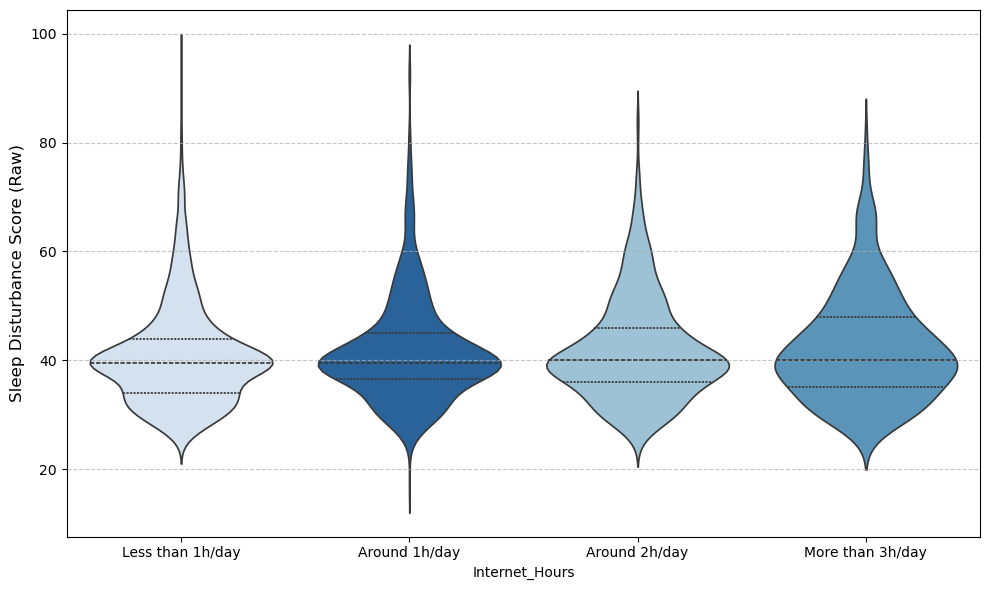

In [21]:
# Violin plot of sleep disturbances (SDS-SDS_Total_Raw) vs daily internet hours (PreInt_EduHx-computerinternet_hoursday)

# Map daily internet hours categories to English labels
hours_map = {
    0.0: 'Less than 1h/day',
    1.0: 'Around 1h/day',
    2.0: 'Around 2h/day',
    3.0: 'More than 3h/day'
}

plot_df = df_da_imp.copy()
# Drop missing values in target columns
plot_df = plot_df.dropna(subset=['PreInt_EduHx-computerinternet_hoursday', 'SDS-SDS_Total_Raw'])
plot_df['Internet_Hours'] = plot_df['PreInt_EduHx-computerinternet_hoursday'].map(hours_map)

# Fixed order for categories and Blues palette
hours_order = ['Less than 1h/day', 'Around 1h/day', 'Around 2h/day', 'More than 3h/day']

# Create single plot
fig, ax = plt.subplots(figsize=(10, 6))

# Violin plot showing the full density distribution and quartiles (dashed lines)
sns.violinplot(
    data=plot_df,
    x='Internet_Hours',
    y='SDS-SDS_Total_Raw',
    order=hours_order,
    hue='Internet_Hours',
    legend=False,
    palette="Blues",
    inner="quart",  # show 25th, 50th, 75th percentiles as quartiles
    ax=ax
)

# Apply layout style matching previous plots (in English, commented title/xlabel)
# ax.set_title('Sleep Disturbances vs. Daily Internet Use', fontsize=14, fontweight='bold', pad=15)
# ax.set_xlabel('Daily Internet/Computer Use', fontsize=12, labelpad=10)
ax.set_ylabel('Sleep Disturbance Score (Raw)', fontsize=12)

# Grid lines
ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

In [25]:
df['SDS-SDS_Total_Raw'].corr(df['SDS-SDS_Total_T'])

np.float64(0.8002248924459374)